(c) Simulate (b) on a ring of N = 200 sites with unit spacing and periodic distance, σe = 1, and σi = 2 and 3. Measure time in units of τw/(qS − qD) and use forward Euler with dt = 0.02 to t = 40, clipping w− to [−1, 1] after each step. Start from w−(a) independent normal with standard deviation 0.01. Plot a final pattern for each σi, and for each σi measure the stripe period (N divided by the number of right/left stripe pairs) over 20 initial conditions. Compare with 2π/k∗, and with the period of the fastest-growing Fourier mode that fits on the ring. Hint: the convolution is fastest with the FFT.

<>:39: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:39: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
C:\Users\laurm\AppData\Local\Temp\ipykernel_23240\193292229.py:39: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
  ax.set_title(f"$\sigma_i = {sigma_i}$")


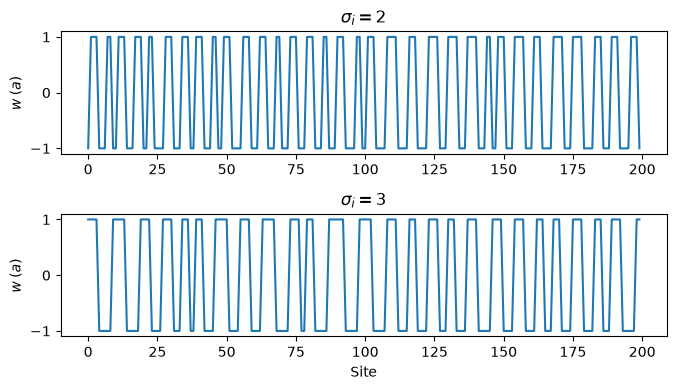

Stripe measurements: {2: array([8., 8., 8., 8., 8., 8., 8., 8., 8., 8., 8., 8., 8., 8., 8., 8., 8.,
       8., 8., 8.]), 3: array([8., 8., 8., 8., 8., 8., 8., 8., 8., 8., 8., 8., 8., 8., 8., 8., 8.,
       8., 8., 8.])}


,sigma_i,Mean measured period,SD,Continuous period (2pi/k*),Fastest growing Fourier mode for ring,Ring-mode period
0,2,8.0,0.0,6.536,31,6.452
1,3,8.0,0.0,8.478,24,8.333


In [17]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Sim parameters
N = 200
dx = 1
sigma_e = 1
sigma_i_values = [2, 3]

# For farward Euler
dt = 0.02
t = 40
n_steps = int(t / dt)

a = np.arange(N)
distance = np.minimum(a, N - a)

def gaussian(x, sigma):
    return np.exp(-x**2 / (2 * sigma**2)) / (np.sqrt(2 * np.pi) * sigma)

def simulate(sigma_i, seed):
    rng = np.random.default_rng(seed)
    k = gaussian(distance, sigma_e) - gaussian(distance, sigma_i)
    k_fft = np.fft.fft(k)
    w = rng.normal(0, 0.01, N)

    for i in range(n_steps):
        dw = np.fft.ifft(k_fft * np.fft.fft(w)).real
        w = np.clip(w + dt * dw, -1, 1)
    
    return w

# Plot final pattern for each sigma_i
fig, axes = plt.subplots(2, 1, figsize = (7, 4))
for ax, sigma_i in zip(axes, sigma_i_values):
    w = simulate(sigma_i, seed=42)
    ax.plot(a, w)
    ax.set_title(f"$\sigma_i = {sigma_i}$")
    ax.set_ylabel("$w_ (a)$")

axes[-1].set_xlabel("Site")
plt.tight_layout()
plt.show()

# Stripe period measurements
results = {}
for val in sigma_i_values: 
    periods = []
    for seed in range(20):
        sgns = np.where(w >= 0, 1, -1)
        n_changes = np.sum(sgns != np.roll(sgns, -1))
        n_pairs = n_changes / 2

        if n_pairs > 0:
            periods.append(N / n_pairs)

    results[val] = np.array(periods)

print(f"Stripe measurements: {results}")

# Comparison between experimental and  2pi/k*
rows = []
for val in sigma_i_values:
    k_star = np.sqrt(2 * np.log(val ** 2 / sigma_e ** 2) / (val ** 2 - sigma_e ** 2))
    P_theoretical = 2 * np.pi / k_star
    K = gaussian(distance, sigma_e) - gaussian(distance, val)
    growth = np.fft.fft(K).real
    modes = np.arange(1, N // 2 + 1)
    m = modes[np.argmax(growth[modes])]
    P_ring = N / m

    rows.append({
        "sigma_i": val, 
        "Mean measured period": np.mean(results[val]),
        "SD": np.std(results[val], ddof = 1),
        "Continuous period (2pi/k*)": P_theoretical,
        "Fastest growing Fourier mode for ring": m, 
        "Ring-mode period": P_ring  
    })

display(pd.DataFrame(rows).round(3))